In [2]:
import pandas as pd
import numpy as np
from sklearn_extra.cluster import KMedoids
import matplotlib.pyplot as plt

ValueError: numpy.dtype size changed, may indicate binary incompatibility. Expected 96 from C header, got 88 from PyObject

In [3]:
# Step 1: Original Data
data = {
    'x': [2, 3, 3, 4, 6, 6, 7, 7, 8, 7],
    'y': [6, 4, 8, 7, 2, 4, 3, 4, 5, 6]
}
df = pd.DataFrame(data)

In [4]:
# Step 2: K-Medoids Clustering using Manhattan Distance
kmedoids = KMedoids(n_clusters=2, metric='manhattan')
kmedoids.fit(df)
df['Cluster'] = kmedoids.labels_
medoids = kmedoids.cluster_centers_

NameError: name 'KMedoids' is not defined

In [5]:
# Step 3: Accept New Point from User
x = float(input("Enter X coordinate of the new point: "))
y = float(input("Enter Y coordinate of the new point: "))
new_point = np.array([[x, y]])

# Step 4: Predict the Cluster for the New Point
cluster_label = kmedoids.predict(new_point)[0]
print(f"The point ({x}, {y}) belongs to Cluster {cluster_label + 1}")

The point (4.0, 6.0) belongs to Cluster 1


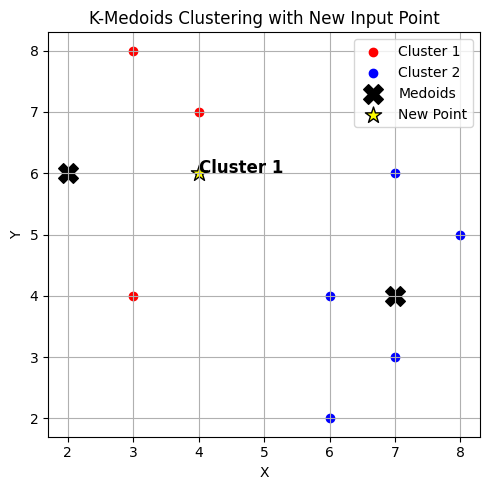

In [6]:
# Step 5: Plot All Points, Medoids, and New Input
plt.figure(figsize=(5, 5))
colors = ['red', 'blue']

# Plot clustered data points
for i in range(2):
    cluster_data = df[df['Cluster'] == i]
    plt.scatter(cluster_data['x'], cluster_data['y'], 
                color=colors[i], label=f'Cluster {i + 1}')

# Plot medoids
plt.scatter(medoids[:, 0], medoids[:, 1], 
            c='black', marker='X', s=200, label='Medoids')

# Plot new point
plt.scatter(x, y, color='yellow', edgecolor='black', 
            s=150, marker='*', label='New Point')

# Show predicted cluster label on the plot
plt.text(x , y, f'Cluster {cluster_label + 1}', 
         fontsize=12, weight='bold', color='black')

# Final touches
plt.xlabel('X')
plt.ylabel('Y')
plt.title('K-Medoids Clustering with New Input Point')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()
